# Dubai Metro ridership: 10-part profile

The same checks as `01_dataset_profile.ipynb`, run on 10 spaced-apart parts of the export, plus a same-second match check, a 1-part versus 10-part comparison, and a check against the official monthly counts.

Tables are saved to `results/profile_10parts/` and charts to `figures/`. Raw files are read from `data/raw/`; set `METRO_DATA_DIR` if they live elsewhere. `assert` lines stop the run if a key number changes.

In [1]:
import os
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

ROOT_DATA = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data" / "raw"
DATA_DIR = Path(os.environ.get("METRO_DATA_DIR", ROOT_DATA))
PART_FILES = sorted(DATA_DIR.glob("metro_ridership_*.csv"))
OFFICIAL = DATA_DIR / "Number_of_Metro_Ridership_by_Lines_2026-11-05.csv"
assert len(PART_FILES) == 10, PART_FILES

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "profile_10parts"
FIGURES = ROOT / "figures"
STATION_MAP = ROOT / "results" / "profile" / "station_map_draft.csv"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Team decisions, 5 Nov 2026
WINDOWS = [("W17/18", "2017-11", "2018-02"), ("W18/19", "2018-09", "2019-02"),
           ("W19/20", "2019-09", "2020-02"), ("W21/22", "2021-09", "2022-02"),
           ("W24/25", "2024-09", "2025-02")]
MIN_TAPS = 300
SENSITIVITY_TAPS = 100
BANDS = [("00-07", 0, 7), ("07-10", 7, 10), ("10-16", 10, 16), ("16-20", 16, 20), ("20-24", 20, 24)]

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
pd.set_option("display.width", 200, "display.max_rows", 120, "display.max_columns", 30)

con = duckdb.connect()
q = lambda sql: con.execute(sql).df()
def save(df, name):
    df.to_csv(RESULTS / f"{name}.csv", index=False)
    return df

## 1. Load the raw parts
All columns are read as text. `part` records which file each row came from.

In [2]:
paths = ",".join("'" + p.as_posix() + "'" for p in PART_FILES)
con.execute(f"""
create table raw as
select right(regexp_replace(filename, '\.csv$', ''), 4) as part,
       end_location, end_zone, line_name, start_location, start_zone,
       txn_date, txn_time, txn_type, load_timestamp,
       substr(txn_date, 1, 4) as yr,
       substr(txn_date, 1, 7) as ym,
       starts_with(txn_time, '00:00:00') as date_only,
       cast(substr(txn_time, 1, 2) as int) as hr,
       cast(txn_date as date) as dt,
       regexp_replace(trim(replace(end_location, ' Metro Station', '')), '\s+', ' ', 'g') as raw_name
from read_csv([{paths}], all_varchar=true, header=true, quote='"', filename=true)
""")
parts = save(q("""
select part, count(*) as n_rows, sum((not date_only)::int) as timed_rows,
       min(txn_date) as first_date, max(txn_date) as last_date
from raw group by 1 order by 1"""), "rows_by_part")
assert parts.n_rows.sum() == 10_484_655
parts

,part,n_rows,timed_rows,first_date,last_date
0,0001,1048468,463515.0,2017-01-01,2026-07-11
1,0002,1048468,463533.0,2017-01-01,2026-07-11
2,0300,1048473,463160.0,2017-01-01,2026-07-11
3,0586,1048463,463050.0,2017-01-01,2026-07-11
4,0900,1048461,463202.0,2017-01-01,2026-07-11
5,1186,1048469,463599.0,2017-01-01,2026-07-11
6,1500,1048470,463716.0,2017-01-01,2026-07-11
7,1786,1048470,463578.0,2017-01-01,2026-07-11
8,2100,1048459,463522.0,2017-01-01,2026-07-11
9,2386,1048454,463603.0,2017-01-01,2026-07-11


## 2. Which column gives the tap station?
Decision: `end_location` for all rows.

In [3]:
tap_station = save(q("""
select txn_type, count(*) as n_rows,
       sum((start_location is null)::int) as start_missing,
       sum((end_location is null)::int) as end_missing,
       sum((start_location is null and end_location is null)::int) as both_missing,
       sum((start_location <> end_location)::int) as columns_disagree
from raw group by 1 order by 1"""), "tap_station_columns")
assert tap_station.end_missing.sum() == tap_station.both_missing.sum()
tap_station

,txn_type,n_rows,start_missing,end_missing,both_missing,columns_disagree
0,Check in,5295523,516875.0,2616.0,2616.0,4735.0
1,Check out,5189132,4476512.0,6755.0,6755.0,0.0


## 3. Same-second matches are kept
Some timed rows match in every column, mostly between neighbouring parts. They are kept: they are twice as common on check-outs, peak at rush hour and rise with station size, so they look like different passengers tapping in the same second. Removing them moved check-ins per check-out from about 1.00 to about 1.015.

In [4]:
key = "end_location, start_location, line_name, txn_date, txn_time, txn_type, load_timestamp"
con.execute(f"""
create table timed as
select * from raw where end_location is not null and not date_only
""")
matches = save(q(f"""
with g as (select {key}, count(*) as copies from timed group by all)
select txn_type, sum(copies) as timed_rows, count(*) as distinct_rows,
       sum(copies) - count(*) as same_second_matches,
       round(100.0 * (sum(copies) - count(*)) / sum(copies), 2) as pct_matches
from g group by 1 order by 1"""), "same_second_matches")
assert matches.timed_rows.sum() == 4_630_593
pairs_shared = save(q(f"""
with d as (select distinct part, {key} from raw where end_location is not null and not date_only)
select a.part as part_a, b.part as part_b, count(*) as shared_timed_rows
from d a join d b
  on a.part < b.part and a.txn_date = b.txn_date and a.txn_time = b.txn_time
 and a.end_location = b.end_location and a.txn_type = b.txn_type
 and a.load_timestamp = b.load_timestamp
 and a.start_location is not distinct from b.start_location
 and a.line_name is not distinct from b.line_name
group by 1, 2 order by 3 desc"""), "shared_rows_by_pair")
display(matches)
pairs_shared

,txn_type,timed_rows,distinct_rows,same_second_matches,pct_matches
0,Check in,2325606.0,2295717,29889.0,1.29
1,Check out,2304987.0,2245363,59624.0,2.59


,part_a,part_b,shared_timed_rows
0,0001,0002,89512
1,0002,1186,1


## 4. Where do real tap times exist?
Outlined cells are the five chosen windows.

,yr,n_rows,timed_rows,pct_date_only
0,2017,1319910,195175.0,85.2
1,2018,1324969,963589.0,27.3
2,2019,1453789,1158164.0,20.3
3,2020,772558,188896.0,75.5
4,2021,1157083,520506.0,55.0
5,2022,720610,424333.0,41.1
6,2023,503972,0.0,100.0
7,2024,1164365,611632.0,47.5
8,2025,1549009,375672.0,75.7
9,2026,518390,196511.0,62.1


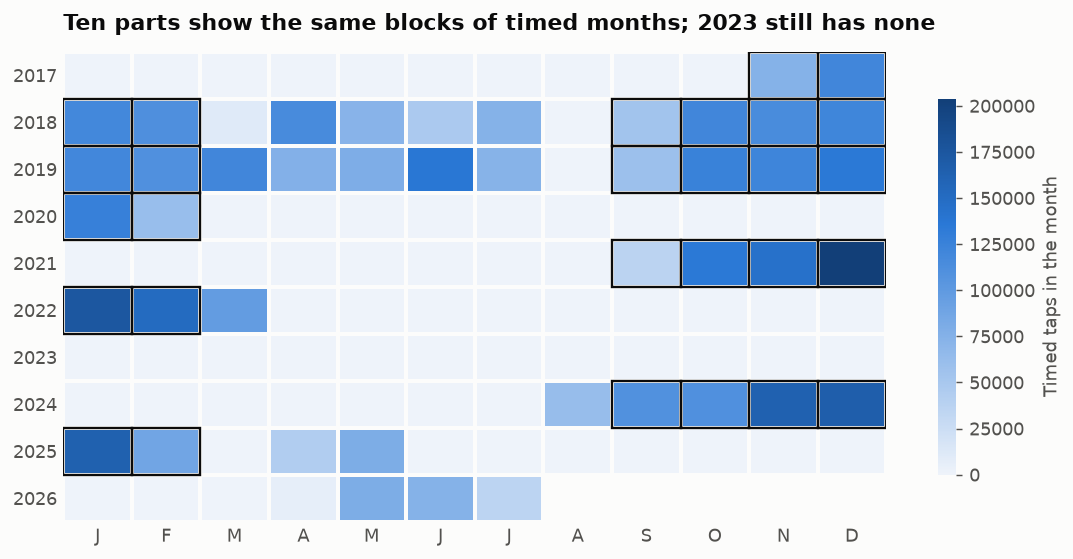

In [5]:
by_year = save(q("""
select yr, count(*) as n_rows, sum((not date_only)::int) as timed_rows,
       round(100.0 * avg(date_only::int), 1) as pct_date_only
from raw group by 1 order by 1"""), "rows_by_year")
months = save(q("""
select yr, cast(substr(ym, 6, 2) as int) as month, count(*) as n_rows, sum((not date_only)::int) as timed_rows
from raw group by 1, 2 order by 1, 2"""), "rows_by_month")
assert by_year.set_index("yr").timed_rows["2023"] == 0

grid = months.pivot(index="yr", columns="month", values="timed_rows")
cmap = LinearSegmentedColormap.from_list("seq", ["#eef3fa", "#8fb8ea", BLUE, "#123f78"])
fig, ax = plt.subplots(figsize=(8.6, 4.4))
im = ax.pcolormesh(grid.values, cmap=cmap, edgecolors=SURFACE, linewidth=2, vmin=0)
ax.invert_yaxis()
ax.set_xticks([i + .5 for i in range(12)], ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_yticks([i + .5 for i in range(len(grid))], grid.index)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
years = list(grid.index)
for _, a, b in WINDOWS:
    for p in pd.period_range(a, b, freq="M"):
        ax.add_patch(Rectangle((p.month - 1, years.index(str(p.year))), 1, 1, fill=False, ec=INK, lw=1.3))
ax.set_title("Ten parts show the same blocks of timed months; 2023 still has none", loc="left", fontsize=12, fontweight="bold", pad=12)
fig.colorbar(im, ax=ax, label="Timed taps in the month", shrink=.8).outline.set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "profile10_timed_months.png", dpi=200)
by_year

## 5. Sampling is uneven inside years

In [6]:
save(q("""
select yr, count(*) as n_rows, round(100.0 * avg((substr(ym, 6, 2) <= '04')::int), 1) as pct_jan_apr
from raw where yr < '2026' group by 1 order by 1"""), "sampling_skew")

,yr,n_rows,pct_jan_apr
0,2017,1319910,34.1
1,2018,1324969,33.4
2,2019,1453789,32.0
3,2020,772558,42.6
4,2021,1157083,24.2
5,2022,720610,86.2
6,2023,503972,10.9
7,2024,1164365,17.8
8,2025,1549009,39.3


## 6. The June 2025 format change

,ym,n_rows,checkin_per_checkout,pct_checkouts_with_start
99,2025-04,133586,1.088,52.1
100,2025-05,134365,1.109,62.1
101,2025-06,114831,1.166,100.0
102,2025-07,104770,1.170,100.0
103,2025-08,106934,1.166,100.0
104,2025-09,107020,1.167,100.0
105,2025-10,128249,1.173,100.0
106,2025-11,124766,1.175,100.0
107,2025-12,119078,1.162,100.0
108,2026-01,111267,1.165,100.0


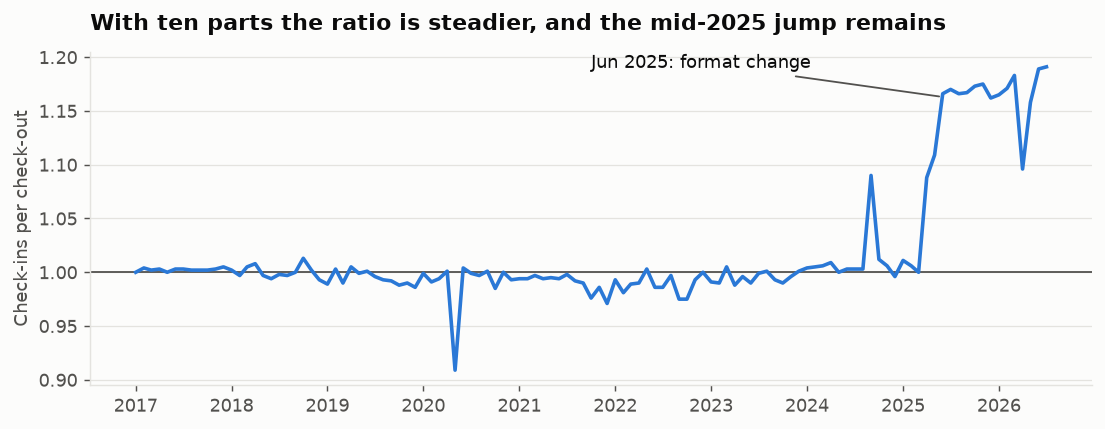

In [7]:
ratio = save(q("""
select ym, count(*) as n_rows,
       round(1.0 * sum((txn_type = 'Check in')::int) / sum((txn_type <> 'Check in')::int), 3) as checkin_per_checkout,
       round(100.0 * sum((txn_type <> 'Check in' and start_location is not null)::int)
             / sum((txn_type <> 'Check in')::int), 1) as pct_checkouts_with_start
from raw group by 1 order by 1"""), "checkin_checkout_ratio")
x = pd.to_datetime(ratio.ym)
fig, ax = plt.subplots(figsize=(8.6, 3.4))
ax.axhline(1, color=MUTED, lw=1)
ax.plot(x, ratio.checkin_per_checkout, color=BLUE, lw=2)
ax.grid(axis="y", color=GRID, lw=.7)
ax.set_ylabel("Check-ins per check-out")
ax.annotate("Jun 2025: format change", (pd.Timestamp("2025-06-01"), 1.163), xytext=(pd.Timestamp("2021-10-01"), 1.19),
            color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_title("With ten parts the ratio is steadier, and the mid-2025 jump remains", loc="left", fontsize=12, fontweight="bold", pad=12)
fig.tight_layout()
fig.savefig(FIGURES / "profile10_checkin_ratio.png", dpi=200)
ratio.tail(16)

## 7. Apply the draft station map
Uses `results/profile/station_map_draft.csv`. Rows with no line fall back to the name alone, except `Sharaf DG`, which is two stations. Renames are still unconfirmed against RTA.

In [8]:
con.execute(f"""
create table station_map as
select raw_name, nullif(line_name, '') as line_name, cast(location_id as int) as location_id, station
from read_csv('{STATION_MAP.as_posix()}', all_varchar=true, header=true)""")
con.execute("""
create table name_only as
select raw_name, min(location_id) as location_id, min(station) as station
from station_map group by 1 having count(distinct location_id) = 1""")
case = " ".join(f"when ym between '{a}' and '{b}' then '{n}'" for n, a, b in WINDOWS)
con.execute(f"""
create table mapped as
select u.*, coalesce(m.location_id, f.location_id) as location_id, coalesce(m.station, f.station) as station,
       case {case} end as win
from timed u
left join station_map m on u.raw_name = m.raw_name and u.line_name is not distinct from m.line_name
left join name_only f on u.raw_name = f.raw_name""")
unmapped = q("select count(*) as n from mapped where location_id is null").n[0]
print("Unmapped unique timed rows:", unmapped, "| stations:", q("select count(distinct location_id) as n from mapped").n[0])
assert unmapped == 0

Unmapped unique timed rows: 0 | stations: 53


## 8. From raw rows to the modelling table

In [9]:
con.execute("create table taps as select * from mapped where win is not null")
points = save(q("""
select win, location_id, station, count(*) as timed_taps,
       sum((txn_type = 'Check in')::int) as check_ins, sum((txn_type <> 'Check in')::int) as check_outs
from taps group by 1, 2, 3 order by 1, 3"""), "station_windows")

total = int(parts.n_rows.sum())
no_station = int(q("select count(*) as n from raw where end_location is null").n[0])
date_only = int(q("select count(*) as n from raw where end_location is not null and date_only").n[0])
timed = int(matches.timed_rows.sum()); in_windows = int(points.timed_taps.sum())
funnel = save(pd.DataFrame([
    ("Raw rows", total), ("No station removed", no_station), ("Date-only removed", date_only),
    ("Timed rows", timed), ("Outside windows removed", timed - in_windows), ("Timed rows in windows", in_windows),
    ("Station-windows", len(points)), (f"Rows at {MIN_TAPS}+ taps", int((points.timed_taps >= MIN_TAPS).sum())),
    (f"Rows at {SENSITIVITY_TAPS}+ taps", int((points.timed_taps >= SENSITIVITY_TAPS).sum()))],
    columns=["step", "rows"]), "funnel")
assert total - no_station - date_only == timed
assert in_windows == 3_340_959
assert len(points) == 245 and (points.timed_taps >= MIN_TAPS).sum() == 244
funnel

,step,rows
0,Raw rows,10484655
1,No station removed,9371
2,Date-only removed,5844691
3,Timed rows,4630593
4,Outside windows removed,1289634
5,Timed rows in windows,3340959
6,Station-windows,245
7,Rows at 300+ taps,244
8,Rows at 100+ taps,245


In [10]:
coverage = save(points.assign(ok=points.timed_taps >= MIN_TAPS, ok100=points.timed_taps >= SENSITIVITY_TAPS).groupby("win").agg(
    stations=("station", "size"), timed_taps=("timed_taps", "sum"), pass_300=("ok", "sum"), pass_100=("ok100", "sum"),
    median_taps=("timed_taps", "median"), min_taps=("timed_taps", "min"),
    check_ins=("check_ins", "sum"), check_outs=("check_outs", "sum")).reset_index()
    .assign(checkin_per_checkout=lambda d: (d.check_ins / d.check_outs).round(3))
    .drop(columns=["check_ins", "check_outs"]), "window_coverage")
display(coverage)
save(points[points.timed_taps < MIN_TAPS], "below_threshold")

,win,stations,timed_taps,pass_300,pass_100,median_taps,min_taps,checkin_per_checkout
0,W17/18,47,425595,47,47,7578.0,310,1.002
1,W18/19,46,641446,45,46,11319.5,254,1.000
2,W19/20,46,630175,46,46,10900.0,580,0.992
3,W21/22,53,843378,53,53,12551.0,485,0.988
4,W24/25,53,800365,53,53,12685.0,1163,1.017


,win,location_id,station,timed_taps,check_ins,check_outs
73,W18/19,157,Energy,254,136.0,118.0


## 9. Are the five time bands well filled?
A cell is one station-window, band and tap direction, for retained rows.

In [11]:
band_case = " ".join(f"when hr >= {lo} and hr < {hi} then '{n}'" for n, lo, hi in BANDS)
con.execute(f"create table banded as select *, case {band_case} end as band from taps")
keep = points[points.timed_taps >= MIN_TAPS][["win", "location_id"]]
con.register("keep", keep)
save(q("""
with c as (
  select b.win, b.location_id, txn_type, band, count(*) as n
  from banded b join keep k on b.win = k.win and b.location_id = k.location_id
  group by all)
select band, cast(median(n) as int) as median_taps, sum((n < 5)::int) as cells_under_5, sum((n < 30)::int) as cells_under_30,
       count(*) as cells_filled, 2 * (select count(*) from keep) as cells_expected
from c group by 1 order by 1"""), "band_cells")

,band,median_taps,cells_under_5,cells_under_30,cells_filled,cells_expected
0,00-07,229,2.0,32.0,488,488
1,07-10,872,0.0,6.0,488,488
2,10-16,1430,0.0,1.0,488,488
3,16-20,1799,0.0,0.0,488,488
4,20-24,998,0.0,5.0,488,488


## 10. Net flow at well-known stations
Pooled over the five windows. Positive means more people leave from the station.

band,station,07-10,16-20
0,Burj Khalifa/ Dubai Mall,-0.660,0.093
1,Business Bay,-0.621,0.496
2,Emirates Towers,-0.326,0.304
3,Dubai Internet City,-0.284,0.244
4,Al Qusais,-0.195,0.278
5,Financial Centre,-0.153,0.088
6,Mall of the Emirates,0.119,-0.051
7,centrepoint,0.236,-0.046
8,Airport Terminal 3,0.271,0.129
9,Etisalat,0.342,-0.122


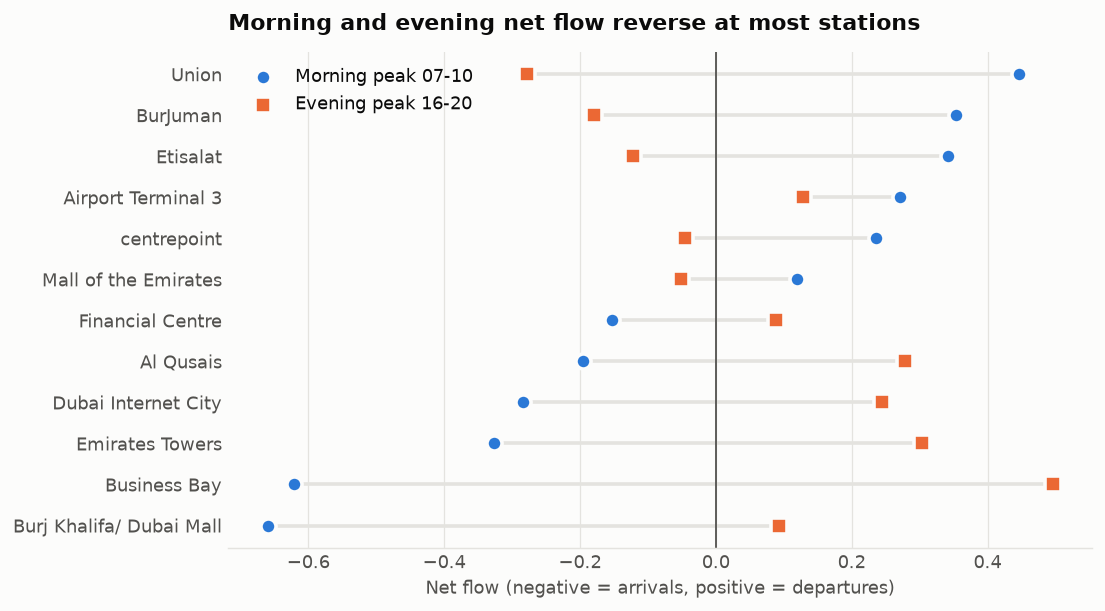

In [12]:
known = ["Business Bay", "Burj Khalifa/ Dubai Mall", "Emirates Towers", "Dubai Internet City", "Financial Centre",
         "Al Qusais", "Mall of the Emirates", "centrepoint", "Etisalat", "Airport Terminal 3", "BurJuman", "Union"]
flow = q("""
select station, band, sum((txn_type = 'Check in')::int) as ci, sum((txn_type <> 'Check in')::int) as co
from banded where band in ('07-10', '16-20') group by 1, 2""")
flow = flow[flow.station.isin(known)].assign(net=lambda d: (d.ci - d.co) / (d.ci + d.co))
flow = save(flow.pivot(index="station", columns="band", values="net").round(3).sort_values("07-10").reset_index(), "net_flow_known_stations")

fig, ax = plt.subplots(figsize=(8.6, 4.8))
y = range(len(flow))
ax.axvline(0, color=MUTED, lw=1)
ax.hlines(y, flow["07-10"], flow["16-20"], color=GRID, lw=2, zorder=1)
ax.scatter(flow["07-10"], y, s=70, color=BLUE, edgecolor=SURFACE, lw=2, label="Morning peak 07-10", zorder=3)
ax.scatter(flow["16-20"], y, s=70, color=ORANGE, marker="s", edgecolor=SURFACE, lw=2, label="Evening peak 16-20", zorder=3)
ax.set_yticks(list(y), flow.station)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Net flow (negative = arrivals, positive = departures)")
ax.grid(axis="x", color=GRID, lw=.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Morning and evening net flow reverse at most stations", loc="left", fontsize=12, fontweight="bold", pad=12)
fig.tight_layout()
fig.savefig(FIGURES / "profile10_net_flow.png", dpi=200)
flow

## 11. Friday and weekend checks

In [13]:
friday = save(q("""
select win,
  round(100.0 * sum((dayname(dt) = 'Friday' and hr < 10)::int) / sum((dayname(dt) = 'Friday')::int), 1) as friday_pct_before_10,
  round(100.0 * sum((dayname(dt) in ('Monday','Tuesday','Wednesday','Thursday') and hr < 10)::int)
        / sum((dayname(dt) in ('Monday','Tuesday','Wednesday','Thursday'))::int), 1) as mon_thu_pct_before_10
from taps group by 1 order by 1"""), "friday_check")
weekdays = save(q("""
select case when yr <= '2021' then 'to 2021' else 'from 2022' end as era, dayname(dt) as weekday,
       round(1.0 * count(*) / count(distinct dt), 0) as rows_per_day
from raw group by 1, 2 order by 1 desc, 3"""), "weekday_volume")
display(friday)
weekdays

,win,friday_pct_before_10,mon_thu_pct_before_10
0,W17/18,1.5,24.7
1,W18/19,2.9,26.1
2,W19/20,2.8,24.9
3,W21/22,13.0,20.0
4,W24/25,25.0,25.4


,era,weekday,rows_per_day
0,to 2021,Friday,2577.0
1,to 2021,Saturday,2889.0
2,to 2021,Monday,3515.0
3,to 2021,Wednesday,3529.0
4,to 2021,Tuesday,3537.0
5,to 2021,Sunday,3569.0
6,to 2021,Thursday,3881.0
7,from 2022,Sunday,2242.0
8,from 2022,Saturday,2681.0
9,from 2022,Thursday,2941.0


## 12. One part versus ten
How much do the same numbers move when each station-window is built from 10 parts instead of `_0001` alone? Compared on rows that pass the minimum in both.

In [14]:
compare = q("""
with one as (
  select win, location_id, band,
         sum((txn_type = 'Check in')::int) as ci, sum((txn_type <> 'Check in')::int) as co
  from banded where part = '0001' group by all),
ten as (
  select win, location_id, band,
         sum((txn_type = 'Check in')::int) as ci, sum((txn_type <> 'Check in')::int) as co
  from banded group by all),
one_tot as (select win, location_id, sum(ci + co) as n from one group by all)
select t.win, t.location_id, t.band,
       (o.ci - o.co) * 1.0 / (o.ci + o.co) as net_one,
       (t.ci - t.co) * 1.0 / (t.ci + t.co) as net_ten
from ten t join one o using (win, location_id, band)
join one_tot n on n.win = t.win and n.location_id = t.location_id
where n.n >= 300""")
compare["gap"] = (compare.net_one - compare.net_ten).abs()
one_vs_ten = save(compare.groupby("band").apply(lambda d: pd.Series({
    "cells": len(d), "correlation": round(d.net_one.corr(d.net_ten), 3),
    "median_gap": round(d.gap.median(), 3), "p95_gap": round(d.gap.quantile(.95), 3)}), include_groups=False).reset_index(), "one_vs_ten_net_flow")
one_vs_ten

,band,cells,correlation,median_gap,p95_gap
0,00-07,227.0,0.932,0.087,0.307
1,07-10,227.0,0.991,0.039,0.136
2,10-16,227.0,0.925,0.030,0.087
3,16-20,227.0,0.988,0.030,0.090
4,20-24,227.0,0.964,0.046,0.157


## 13. Check against official monthly counts
Station shares in W24/25 against the official monthly rider file, for stations whose names match in both.

In [15]:
con.execute(f"""
create table official as
select distinct Title, Line, cast(Year as int) as y, cast(Month_Number as int) as m, cast(Value as bigint) as v
from read_csv('{OFFICIAL.as_posix()}', all_varchar=true, header=true, sample_size=-1)""")
official = q(r"""
select lower(trim(regexp_replace(regexp_replace(Title, '[*]+', ''), ' - (Red|Green) Line', ''))) as k, sum(v) as riders
from official where (y = 2024 and m >= 9) or (y = 2025 and m <= 2) group by 1""")
ours = points[points.win == "W24/25"].assign(k=lambda d: d.station.str.lower())
both = official.merge(ours[["k", "timed_taps"]], on="k")
both["official_pct"] = 100 * both.riders / both.riders.sum()
both["sample_pct"] = 100 * both.timed_taps / both.timed_taps.sum()
both["ratio"] = both.sample_pct / both.official_pct
print(len(both), "stations matched | correlation", round(both.official_pct.corr(both.sample_pct), 4),
      "| timed taps per 1,000 riders", round(1000 * both.timed_taps.sum() / both.riders.sum(), 2))
save(both.sort_values("ratio").round(3), "official_comparison")

47 stations matched | correlation 0.9981 | timed taps per 1,000 riders 5.39


,k,riders,timed_taps,official_pct,sample_pct,ratio
9,dubai airport free zone,2497151.0,12311,1.783,1.630,0.914
38,creek,739223.0,3650,0.528,0.483,0.916
1,emirates,1526838.0,7539,1.090,0.998,0.916
21,dmcc,4662884.0,23223,3.329,3.075,0.924
12,airport terminal 3,1040389.0,5316,0.743,0.704,0.948
36,airport terminal 1,1812572.0,9263,1.294,1.227,0.948
17,discovery gardens,801424.0,4139,0.572,0.548,0.958
2,emirates towers,3224104.0,16713,2.302,2.213,0.961
7,al qusais,1344586.0,7018,0.960,0.929,0.968
14,oud metha,3076638.0,16098,2.196,2.132,0.970
